<a href="https://colab.research.google.com/github/CHETANAREDDYMALLA/edav_project/blob/main/course_end_project_118.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
# Install dependencies as needed:
import kagglehub
from kagglehub import KaggleDatasetAdapter

# Set the path to the file you'd like to load from the dataset
file_path = "Metro_Interstate_Traffic_Volume.csv"

# Load the latest version using the recommended dataset_load
df = kagglehub.dataset_load(
  KaggleDatasetAdapter.PANDAS,
  "anshtanwar/metro-interstate-traffic-volume",
  file_path
)

print("First 5 records:")
print(df.head())

Using Colab cache for faster access to the 'metro-interstate-traffic-volume' dataset.
First 5 records:
   traffic_volume holiday    temp  rain_1h  snow_1h  clouds_all weather_main  \
0            5545     NaN  288.28      0.0      0.0          40       Clouds   
1            4516     NaN  289.36      0.0      0.0          75       Clouds   
2            4767     NaN  289.58      0.0      0.0          90       Clouds   
3            5026     NaN  290.13      0.0      0.0          90       Clouds   
4            4918     NaN  291.14      0.0      0.0          75       Clouds   

  weather_description         date_time  
0    scattered clouds  02-10-2012 09:00  
1       broken clouds  02-10-2012 10:00  
2     overcast clouds  02-10-2012 11:00  
3     overcast clouds  02-10-2012 12:00  
4       broken clouds  02-10-2012 13:00  


In [4]:
!pip install kagglehub[pandas-datasets]


setup

In [9]:
# Data types, missing values, duplicates, summary statisticsdf.info()
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate timestamps:", df.duplicated(subset="date_time").sum())
df.describe()


Missing values:
 traffic_volume             0
holiday                48143
temp                       0
rain_1h                    0
snow_1h                    0
clouds_all                 0
weather_main               0
weather_description        0
date_time                  0
dtype: int64

Duplicate rows: 17
Duplicate timestamps: 7629


,traffic_volume,temp,rain_1h,snow_1h,clouds_all
count,48204.000000,48204.000000,48204.000000,48204.000000,48204.000000
mean,3259.818355,281.205870,0.334264,0.000222,49.362231
std,1986.860670,13.338232,44.789133,0.008168,39.015750
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1193.000000,272.160000,0.000000,0.000000,1.000000
50%,3380.000000,282.450000,0.000000,0.000000,64.000000
75%,4933.000000,291.806000,0.000000,0.000000,90.000000
max,7280.000000,310.070000,9831.300000,0.510000,100.000000


In [12]:
df["date_time"] = pd.to_datetime(df["date_time"], format="mixed")
df["hour"] = df["date_time"].dt.hour
df["day_name"] = df["date_time"].dt.day_name()
df["month"] = df["date_time"].dt.month
df["is_weekend"] = df["date_time"].dt.dayofweek >= 5  # True = Sat/Sun
df["day_type"] = np.where(df["is_weekend"], "Weekend", "Weekday")
# Time-of-day buckets
bins = [-1, 5, 9, 15, 19, 23]
labels = [
    "Night (0-5)",
    "Morning Rush (6-9)",
    "Midday (10-15)",
    "Evening Rush (16-19)",
    "Late Evening (20-23)",
]
df["time_of_day"] = pd.cut(df["hour"], bins=bins, labels=labels)
df[
    [
        "date_time",
        "hour",
        "day_name",
        "day_type",
        "time_of_day",
        "traffic_volume",
    ]
].head()

,date_time,hour,day_name,day_type,time_of_day,traffic_volume
0,2012-02-10 09:00:00,9,Friday,Weekday,Morning Rush (6-9),5545
1,2012-02-10 10:00:00,10,Friday,Weekday,Midday (10-15),4516
2,2012-02-10 11:00:00,11,Friday,Weekday,Midday (10-15),4767
3,2012-02-10 12:00:00,12,Friday,Weekday,Midday (10-15),5026
4,2012-02-10 13:00:00,13,Friday,Weekday,Midday (10-15),4918


## Q1. NumPy: Average, Min and Max Traffic Volume by Day Type and Holiday Status  [CO1, BL3]
**Concept:** Convert columns to NumPy arrays, use boolean masks to split traffic volume into groups, and compute mean/min/max with NumPy functions.

In [13]:
# Handle missing values temporarily (drop rows where needed columns are NaN)
tmp = df.dropna(subset=["traffic_volume", "is_weekend"])
vol = tmp["traffic_volume"].to_numpy(dtype=float)
weekend = tmp["is_weekend"].to_numpy()
print("--- Traffic volume by day type ---")
for name, mask in [("Weekday", ~weekend), ("Weekend", weekend)]:
    v = vol[mask]
    print(f"{name:8s} | n={v.size:6d} | mean={np.mean(v):8.1f} | min={np.min(v):6.0f} | max={np.max(v):6.0f} | std={np.std(v):7.1f}")
# Holiday vs non-holiday (holiday is NaN / 'None' on regular days)
is_holiday = (tmp["holiday"].notna() & (tmp["holiday"] != "None")).to_numpy()
print("\n--- Traffic volume by holiday status ---")
for name, mask in [("Holiday", is_holiday), ("Non-holiday", ~is_holiday)]:
    v = vol[mask]
    print(f"{name:12s} | n={v.size:6d} | mean={np.mean(v):8.1f} | min={np.min(v):6.0f} | max={np.max(v):6.0f}")

--- Traffic volume by day type ---
Weekday  | n= 34468 | mean=  3439.7 | min=     1 | max=  7260 | std= 2045.3
Weekend  | n= 13736 | mean=  2808.4 | min=     0 | max=  7280 | std= 1752.4

--- Traffic volume by holiday status ---
Holiday      | n=    61 | mean=   865.4 | min=   455 | max=  1538
Non-holiday  | n= 48143 | mean=  3262.9 | min=     0 | max=  7280


## Q2. Pandas: How Hour, Day and Weather Influence Traffic Volume  [CO2, BL4]
**Concept:** Use `groupby` with aggregation to find which time periods and weather conditions carry the most traffic.

In [14]:
# Average traffic by hour of day
by_hour = df.groupby("hour")["traffic_volume"].agg(["mean", "median", "max", "count"]).round(1)
print(by_hour.sort_values("mean", ascending=False).head(5))
# Average traffic by day of week
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
by_day = df.groupby("day_name")["traffic_volume"].agg(["mean", "median", "count"]).reindex(order).round(1)
print("\n", by_day)
# Average traffic by weather
by_weather = df.groupby("weather_main")["traffic_volume"].agg(["mean", "median", "count"]).sort_values("mean", ascending=False).round(1)
print("\n", by_weather)
# Day type x time of day
pd.pivot_table(df, values="traffic_volume", index="time_of_day", columns="day_type", aggfunc="mean", observed=True).round(1)

        mean  median   max  count
hour                             
16    5663.8  6167.0  7280   1988
17    5310.1  5719.0  6968   1933
15    5240.5  5554.0  6750   1934
14    4931.9  5065.0  6589   1969
7     4740.2  5998.0  7260   2079

              mean  median  count
day_name                        
Monday     3306.0  3453.0   6873
Tuesday    3421.9  3680.0   6864
Wednesday  3488.2  4043.0   6906
Thursday   3492.2  3723.5   6850
Friday     3489.4  3869.0   6975
Saturday   2916.0  3030.0   6875
Sunday     2700.7  2697.0   6861

                 mean  median  count
weather_main                       
Clouds        3618.4  4072.0  15164
Haze          3502.1  3987.0   1360
Rain          3317.9  3497.5   5672
Drizzle       3290.7  3473.0   1821
Smoke         3237.6  3612.0     20
Clear         3055.9  3045.0  13391
Snow          3016.8  3080.0   2876
Thunderstorm  3001.6  2971.5   1034
Mist          2933.0  2800.0   5950
Fog           2703.7  2339.0    912
Squall        2061.8  1818.0 

day_type,Weekday,Weekend
time_of_day,,
Night (0-5),854.8,737.4
Morning Rush (6-9),5100.0,2895.9
Midday (10-15),4843.0,4351.9
Evening Rush (16-19),4815.4,4151.6
Late Evening (20-23),2263.7,2345.9


## Q3. Handling Missing Values, Outliers and Duplicates  [CO3, BL3]
**Concept:** Prepare a clean dataset. Besides NaNs, this dataset has known data-entry issues: `temp = 0 K` (impossible), an extreme `rain_1h` outlier (thousands of mm), and repeated timestamps.

In [15]:
clean = df.copy()
# 1) Duplicates: remove exact duplicates and repeated timestamps (keep first)
before = len(clean)
clean = clean.drop_duplicates()
clean = clean.drop_duplicates(subset="date_time", keep="first")
print("Rows removed (duplicates):", before - len(clean))
# 2) Incorrect entries -> mark as NaN so they can be imputed
clean.loc[clean["temp"] <= 0, "temp"] = np.nan            # 0 Kelvin is impossible
clean.loc[clean["rain_1h"] > 100, "rain_1h"] = np.nan      # >100 mm/hour is a sensor error
# 3) Impute numeric columns with the median (robust to outliers)
for col in ["temp", "rain_1h", "snow_1h", "clouds_all"]:
    clean[col] = clean[col].fillna(clean[col].median())
# 4) Impute categorical columns with a placeholder
clean["holiday"] = clean["holiday"].replace("None", np.nan).fillna("No Holiday")
clean["weather_main"] = clean["weather_main"].fillna("Unknown")
clean["weather_description"] = clean["weather_description"].fillna("Unknown")
# 5) Convert temperature to Celsius for readability
clean["temp_c"] = clean["temp"] - 273.15
# 6) Target-style flag: high traffic = above 75th percentile
threshold = clean["traffic_volume"].quantile(0.75)
clean["high_traffic"] = (clean["traffic_volume"] > threshold).astype(int)
# Verify nothing is missing
print("High-traffic threshold:", threshold)
print("Remaining missing values:", int(clean[["temp","rain_1h","snow_1h","clouds_all","holiday","weather_main","traffic_volume"]].isnull().sum().sum()))
clean.describe().round(2)

Rows removed (duplicates): 7629
High-traffic threshold: 4952.0
Remaining missing values: 0


,traffic_volume,temp,rain_1h,snow_1h,clouds_all,date_time,hour,month,temp_c,high_traffic
count,40575.00,40575.00,40575.00,40575.00,40575.00,40575,40575.00,40575.00,40575.00,40575.00
mean,3290.65,281.39,0.08,0.00,44.20,2015-12-25 00:13:50.728280832,11.51,6.53,8.24,0.25
min,0.00,243.39,0.00,0.00,0.00,2012-01-11 00:00:00,0.00,1.00,-29.76,0.00
25%,1248.50,271.85,0.00,0.00,1.00,2014-02-13 21:30:00,5.00,4.00,-1.30,0.00
50%,3427.00,282.87,0.00,0.00,40.00,2016-05-25 11:00:00,12.00,7.00,9.72,0.00
75%,4952.00,292.28,0.00,0.00,90.00,2017-08-02 23:30:00,18.00,9.00,19.13,0.00
max,7280.00,310.07,55.63,0.51,100.00,2018-12-09 23:00:00,23.00,12.00,36.92,1.00
std,1984.77,13.09,0.77,0.01,38.68,NaN,6.95,3.40,13.09,0.43


## Q4. Group by Weather and Day Type: Descriptive Statistics  [CO4, BL4]
**Concept:** Like grouping by `['Embarked','Survived']`, here we group by `['weather_main','high_traffic']` and by `['weather_main','day_type']` to compute counts and means.

In [16]:
# Counts and share of high-traffic hours per weather type
g1 = clean.groupby(["weather_main", "high_traffic"])["traffic_volume"].agg(["count", "mean"]).round(1)
print(g1)
# Probability of high traffic by weather (analogous to survival rate by port)
prob = clean.groupby("weather_main")["high_traffic"].agg(["count", "mean"]).rename(columns={"mean": "p_high_traffic"})
print("\n", prob.sort_values("p_high_traffic", ascending=False).round(3))
# Weather x day type
g2 = clean.groupby(["weather_main", "day_type"])["traffic_volume"].agg(["count", "mean", "median", "std"]).round(1)
g2

                           count    mean
weather_main high_traffic               
Clear        0             10435  2309.7
             1              2931  5709.6
Clouds       0             10789  2766.4
             1              4334  5734.5
Drizzle      0               389  2318.0
             1               126  5758.9
Fog          0               142  1412.0
             1                59  5883.2
Haze         0               562  2876.2
             1               204  5586.1
Mist         0              2308  1879.2
             1               761  5811.3
Rain         0              3532  2533.4
             1              1237  5701.9
Smoke        0                14  2323.9
             1                 1  5861.0
Snow         0              1893  2437.0
             1               404  5648.4
Squall       0                 1   420.0
Thunderstorm 0               368  2344.7
             1                85  5801.6

               count  p_high_traffic
weather_main       

count    mean  median     std
weather_main day_type                               
Clear        Weekday    9425  3217.2  3199.0  2066.7
             Weekend    3941  2668.1  2692.0  1721.9
Clouds       Weekday   10869  3764.0  4378.0  1962.4
             Weekend    4254  3241.3  3550.0  1700.2
Drizzle      Weekday     356  3406.6  3508.0  2117.9
             Weekend     159  2607.3  2631.0  1701.9
Fog          Weekday     129  2928.0  2453.0  2410.1
             Weekend      72  2359.7  1611.0  2081.8
Haze         Weekday     580  3695.1  4366.0  1863.6
             Weekend     186  3295.0  3688.0  1652.2
Mist         Weekday    2129  3100.5  2837.0  2243.5
             Weekend     940  2296.3  1770.5  1835.4
Rain         Weekday    3546  3517.8  4074.5  2028.0
             Weekend    1223  2884.1  3009.0  1746.0
Smoke        Weekday       9  1531.4   890.0  1324.3
             Weekend       6  4102.0  4351.0  1170.9
Snow         Weekday    1662  3216.6  3451.5  1950.2
             Weekend     635  2439.8  2292.0  1629.1
Squall       Weekday       1   420.0   420.0     NaN
Thunderstorm Weekday     322  3264.1  3281.5  1988.2
             Weekend     131  2327.8  2329.0  1673.2

## Q5. Bar Plots and Heatmaps  [CO5, BL5]
**Concept:** Present the findings visually with labeled axes, titles and legends.

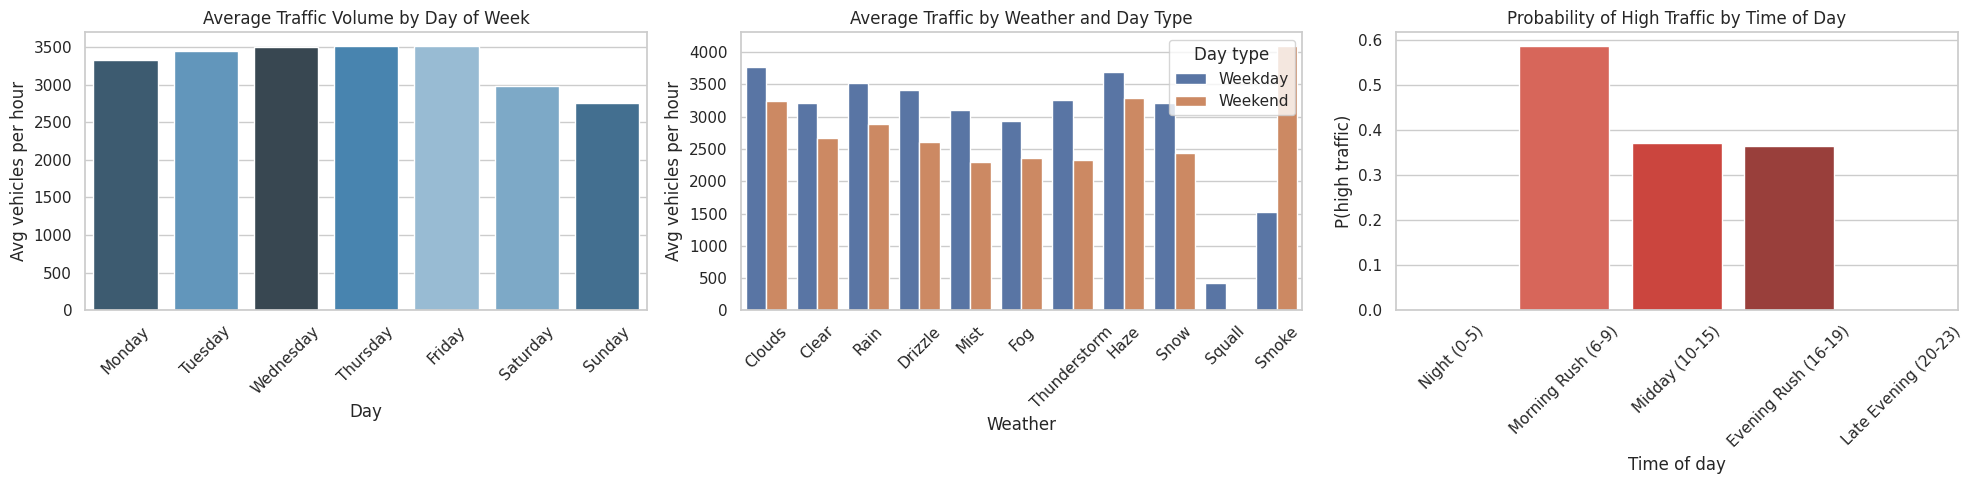

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
# Bar 1: average traffic by day of week
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
sns.barplot(data=clean, x="day_name", y="traffic_volume", order=order, errorbar=None, hue="day_name", legend=False, palette="Blues_d", ax=axes[0])
axes[0].set(title="Average Traffic Volume by Day of Week", xlabel="Day", ylabel="Avg vehicles per hour")
axes[0].tick_params(axis="x", rotation=45)
# Bar 2: average traffic by weather, split by day type
sns.barplot(data=clean, x="weather_main", y="traffic_volume", hue="day_type", errorbar=None, ax=axes[1])
axes[1].set(title="Average Traffic by Weather and Day Type", xlabel="Weather", ylabel="Avg vehicles per hour")
axes[1].tick_params(axis="x", rotation=45)
axes[1].legend(title="Day type")
# Bar 3: probability of high traffic by time of day
sns.barplot(data=clean, x="time_of_day", y="high_traffic", errorbar=None, hue="time_of_day", legend=False, palette="Reds_d", ax=axes[2])
axes[2].set(title="Probability of High Traffic by Time of Day", xlabel="Time of day", ylabel="P(high traffic)")
axes[2].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

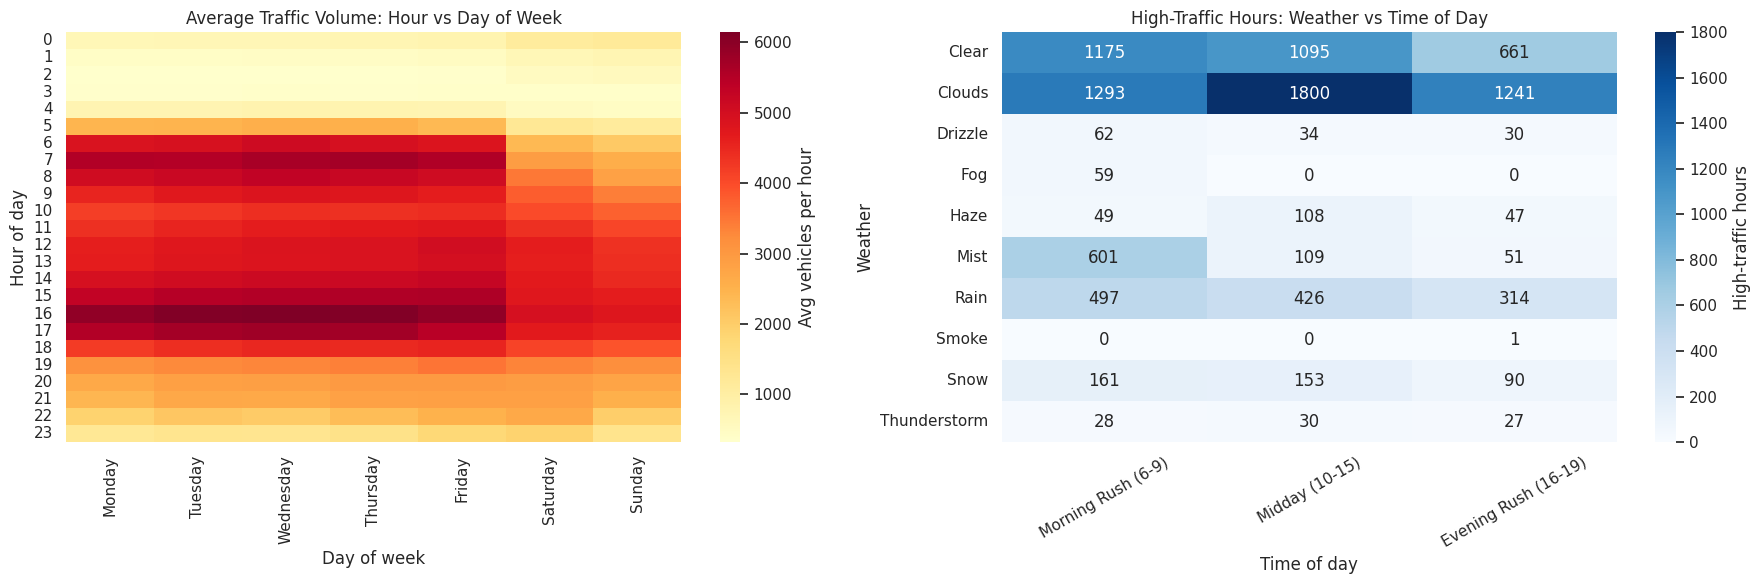

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
# Heatmap 1: average traffic by hour x day of week
pivot1 = clean.pivot_table(values="traffic_volume", index="hour", columns="day_name", aggfunc="mean")[order]
sns.heatmap(pivot1, cmap="YlOrRd", ax=axes[0], cbar_kws={"label": "Avg vehicles per hour"})
axes[0].set(title="Average Traffic Volume: Hour vs Day of Week", xlabel="Day of week", ylabel="Hour of day")
# Heatmap 2: count of high-traffic hours by weather x time of day
pivot2 = clean[clean["high_traffic"] == 1].pivot_table(values="traffic_volume", index="weather_main", columns="time_of_day", aggfunc="count", observed=True).fillna(0)
sns.heatmap(pivot2, annot=True, fmt=".0f", cmap="Blues", ax=axes[1], cbar_kws={"label": "High-traffic hours"})
axes[1].set(title="High-Traffic Hours: Weather vs Time of Day", xlabel="Time of day", ylabel="Weather")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

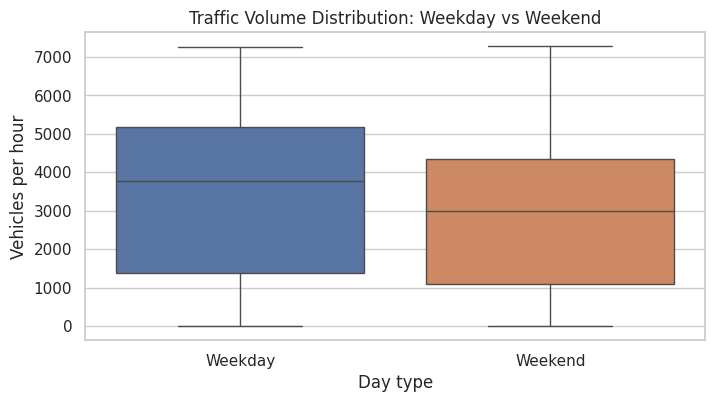

In [19]:
# Outlier check on the cleaned data
plt.figure(figsize=(8, 4))
sns.boxplot(data=clean, x="day_type", y="traffic_volume", hue="day_type", legend=False)
plt.title("Traffic Volume Distribution: Weekday vs Weekend")
plt.xlabel("Day type"); plt.ylabel("Vehicles per hour")
plt.show()

**Insight:** Describe the rush-hour bands visible in the heatmap, the weekday/weekend gap, and which weather types appear most often in high-traffic hours (remember that count heatmaps are affected by how often each weather type occurs).

## Final Conclusion
1. **Time:** Traffic peaks during morning and evening rush hours on weekdays.
2. **Day type:** Weekends and holidays carry noticeably less traffic.
3. **Weather:** Summarize whether weather changes traffic meaningfully once time of day is accounted for.
4. **Data quality:** Mention the duplicates, 0 K temperatures and extreme rainfall values that were corrected.
5. **Limitations:** Single sensor location, and correlation does not imply causation.